### Brain Tumor Segmentation(BraTS2020)
See details here: https://www.kaggle.com/datasets/awsaf49/brats2020-training-data

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import random
from pathlib import Path

from torchvision import transforms

print("PyTorch version:", torch.__version__)

PyTorch version: 2.10.0


In [3]:
import h5py

In [4]:
#REPRODUCIBILITY

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [5]:
# import kagglehub
# path = kagglehub.dataset_download(
    #"awsaf49/brats2020-training-data")

#path already exists on this path so no need to download.
path = "/Users/blessing/Desktop/HackBio-internship/AI4Genomics/data/brats2020"
print("Path to dataset files:", path)


Path to dataset files: /Users/blessing/Desktop/HackBio-internship/AI4Genomics/data/brats2020


In [6]:
#metadata['slice_path'][0]
#get the base directory
ARCHIVE_DIR = '/Users/blessing/Desktop/HackBio-internship/AI4Genomics/data/brats2020/BraTS2020_training_data/content/data/'
FILE_NAMES = os.listdir(ARCHIVE_DIR)

In [7]:
FILE_NAMES

['volume_54_slice_149.h5',
 'volume_95_slice_145.h5',
 'volume_137_slice_59.h5',
 'volume_354_slice_45.h5',
 'volume_190_slice_82.h5',
 'volume_19_slice_43.h5',
 'volume_104_slice_103.h5',
 'volume_238_slice_147.h5',
 'volume_96_slice_102.h5',
 'volume_305_slice_8.h5',
 'volume_107_slice_144.h5',
 'volume_60_slice_80.h5',
 'volume_185_slice_34.h5',
 'volume_151_slice_103.h5',
 'volume_178_slice_128.h5',
 'volume_58_slice_19.h5',
 'volume_308_slice_77.h5',
 'volume_333_slice_1.h5',
 'volume_45_slice_71.h5',
 'volume_286_slice_127.h5',
 'volume_193_slice_148.h5',
 'volume_152_slice_144.h5',
 'volume_321_slice_6.h5',
 'volume_325_slice_58.h5',
 'volume_338_slice_30.h5',
 'volume_213_slice_47.h5',
 'volume_146_slice_44.h5',
 'volume_75_slice_36.h5',
 'volume_353_slice_27.h5',
 'volume_278_slice_50.h5',
 'volume_265_slice_38.h5',
 'volume_146_slice_124.h5',
 'volume_187_slice_128.h5',
 'volume_292_slice_147.h5',
 'volume_248_slice_17.h5',
 'volume_363_slice_60.h5',
 'volume_279_slice_127.h5

In [8]:
len(FILE_NAMES)

57198

In [9]:
RANDOM_SELECT = random.randint(0,len(FILE_NAMES))
print(RANDOM_SELECT)

41905


/Users/blessing/Desktop/HackBio-internship/AI4Genomics/data/brats2020/BraTS2020_training_data/content/data/volume_54_slice_149.h5
<KeysViewHDF5 ['image', 'mask']>
<HDF5 dataset "image": shape (240, 240, 4), type "<f8">
<HDF5 dataset "mask": shape (240, 240, 3), type "|u1">
[[-0.25131582 -0.25131582 -0.25131582 ... -0.25131582 -0.25131582
  -0.25131582]
 [-0.25131582 -0.25131582 -0.25131582 ... -0.25131582 -0.25131582
  -0.25131582]
 [-0.25131582 -0.25131582 -0.25131582 ... -0.25131582 -0.25131582
  -0.25131582]
 ...
 [-0.25131582 -0.25131582 -0.25131582 ... -0.25131582 -0.25131582
  -0.25131582]
 [-0.25131582 -0.25131582 -0.25131582 ... -0.25131582 -0.25131582
  -0.25131582]
 [-0.25131582 -0.25131582 -0.25131582 ... -0.25131582 -0.25131582
  -0.25131582]]


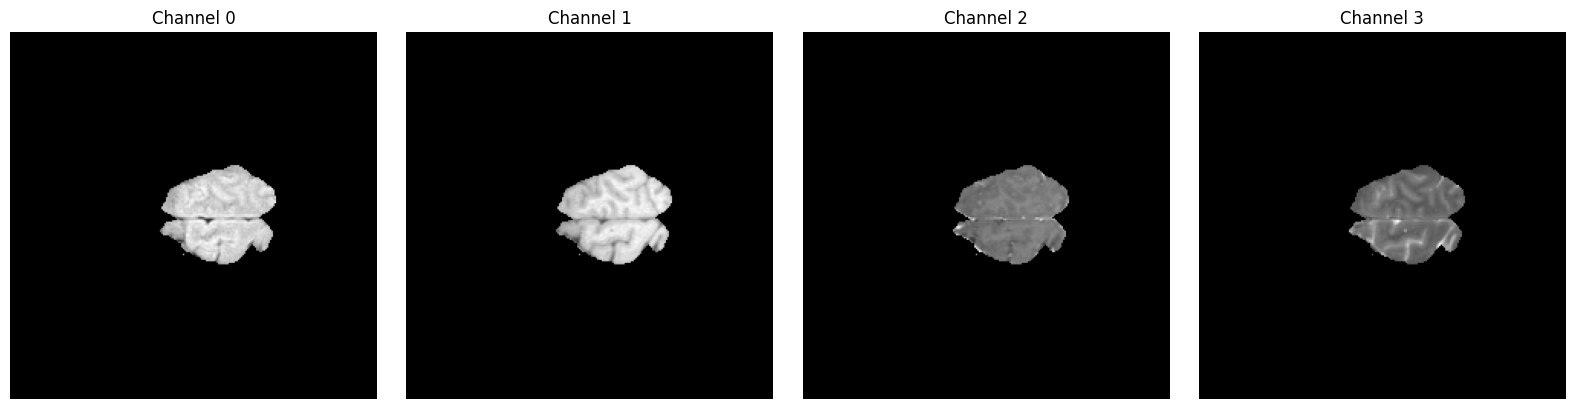

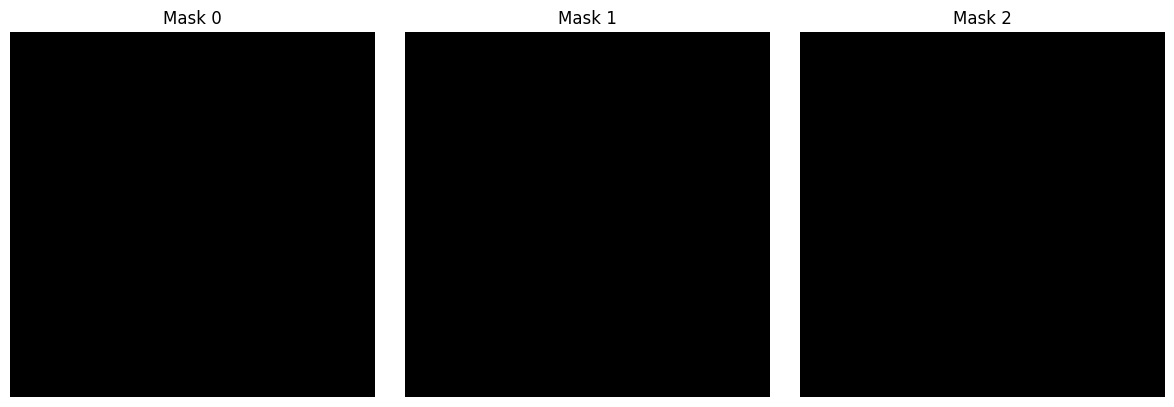

In [10]:
RANDOM_SELECT = random.randint(0,len(FILE_NAMES))

#test file loading
print(ARCHIVE_DIR + FILE_NAMES[0])

TEST_FILE = h5py.File(ARCHIVE_DIR+FILE_NAMES[RANDOM_SELECT], 'r')

print(TEST_FILE.keys())
print(TEST_FILE['image'])
print(TEST_FILE['mask'])

#View test file
img = (TEST_FILE['image'])
mask = (TEST_FILE['mask'])

#
print(img[:, :, 1])

#MODALITIES = ['T1','T1ice', 'T2', 'FLAIR']
MODALITIES = [0,1,2,3]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for i in range(4):
    axes[i].imshow(img[:, :, i], cmap='gray')
    axes[i].set_title(f'Channel {MODALITIES[i]}')
    axes[i].axis('off')
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i in range(3):
    axes[i].imshow(mask[:, :, i], cmap='gray')
    axes[i].set_title(f'Mask {i}')
    axes[i].axis('off')
plt.tight_layout()
plt.show()

Modality	File suffix	What it shows
T1-weighted	0	Anatomical brain structure
T1 with contrast enhancement	1	Highlights enhancing tumor regions
T2-weighted	2	Shows edema and fluid
FLAIR	3	Suppresses CSF, highlights edema and lesions


In [11]:
print(img.shape)
print(mask.shape)

(240, 240, 4)
(240, 240, 3)


In [12]:
'volume_54_slice_149.h5'.split('.')[-1]

'h5'

In [13]:
class BratsSegmentationDataset(Dataset):
    def __init__(self, img_size = (240,240)):
        #self.file_names = FILE_NAMES
        self.img_size = img_size
        self.files = []

        for file in FILE_NAMES:
            if not file.endswith('.h5'):
                continue
                
            file_path = ARCHIVE_DIR + file

            with h5py.File(file_path, "r") as f:
                img = f["image"][:]
                mask = f["mask"][:]
                #print(img.shape[:2])

            if img.shape[:2] != (240, 240):
                continue
            if mask.shape[:2] != (240, 240):
                continue
            if img.shape[2] != 4:
                continue
            if mask.shape[2] != 3:
                continue
            #clean up masks 
            tumor_mask = mask.sum(axis=2)
            #print(tumor_mask.sum())
            if tumor_mask.sum() == 0:
                continue

            #append only clean files with a mask
            self.files.append(file_path)
        print(f"Valid non-empty samples: {len(self.files)}")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        Image_path = self.files[idx]
        #print(Image_path)
        IMG_FILE = h5py.File(Image_path, 'r')

        img = IMG_FILE['image']
        mask = IMG_FILE['mask'][:]
        #print(mask)

        #return only FLAIR
        img = torch.tensor(img[:, :, 3], dtype=torch.float32).unsqueeze(0)
        img = (img - img.min()) / (img.max() - img.min() + 1e-8) #normalize

        tumor_mask = mask.sum(axis=2)
        mask = torch.tensor(tumor_mask, dtype=torch.float32).unsqueeze(0)
    
        return {
            'image': img,
            'mask': mask
        }

In [14]:
BRAT_DATASET = BratsSegmentationDataset()
print('Number of image-mask pair: ', len(BRAT_DATASET))

Valid non-empty samples: 24422
Number of image-mask pair:  24422


In [15]:
RANDOM_SELECT

7296

In [16]:
BRAT_DATASET[RANDOM_SELECT]['image'].dtype

torch.float32

In [17]:
BRAT_DATASET[RANDOM_SELECT]['mask']

tensor([[[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         ...,
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.]]])

In [18]:
#generate 3 random figures
RANDOM_COLLECTION = []
for i in range(3):
    RANDOM_COLLECTION.append(random.randint(0,len(BRAT_DATASET)))

print(RANDOM_COLLECTION)

[819, 24299, 9012]


(240, 240, 4) (240, 240, 3)
(240, 240, 4) (240, 240, 3)
(240, 240, 4) (240, 240, 3)


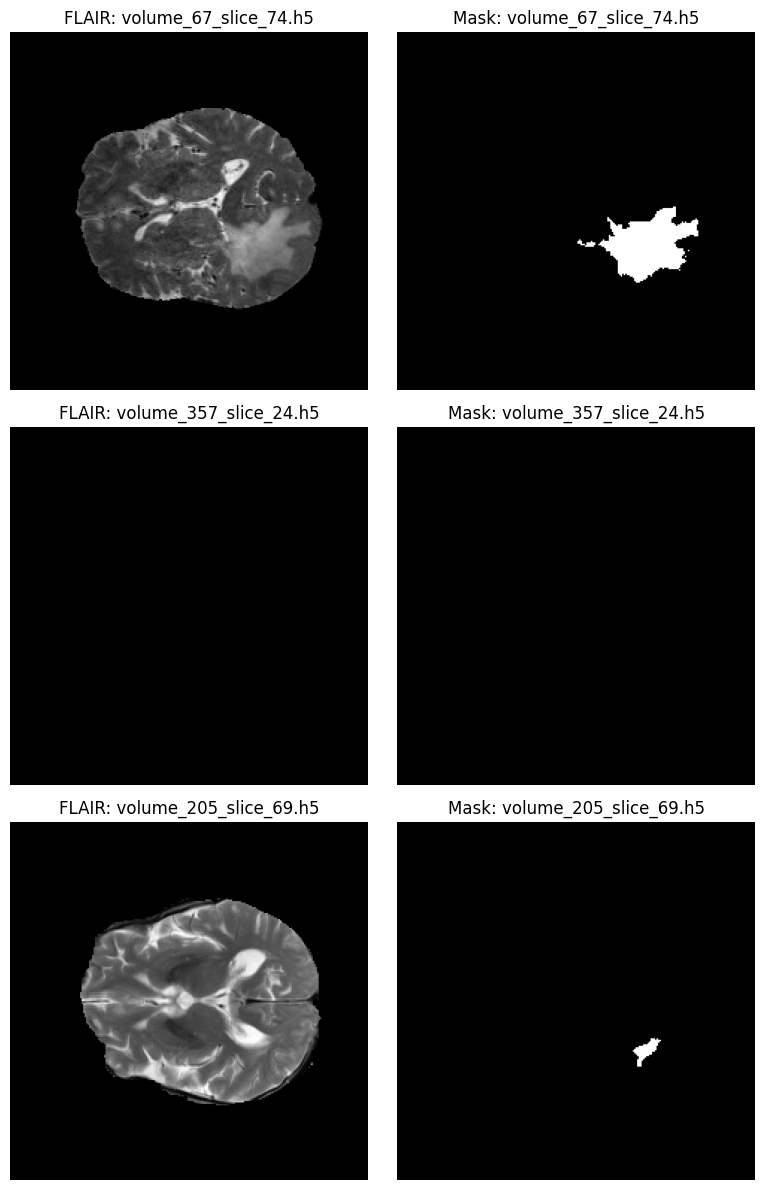

In [19]:
fig, axes = plt.subplots(len(RANDOM_COLLECTION), 2, figsize=(8,4 * len(RANDOM_COLLECTION)))
# Handle case with only one sample
if len(RANDOM_COLLECTION) == 1:
    axes = [axes]
for i, f_samp in enumerate(RANDOM_COLLECTION):
    with h5py.File(ARCHIVE_DIR + FILE_NAMES[f_samp], 'r') as f:
        img = f['image'][:]
        mask = f['mask'][:]
        print(img.shape, mask.shape)
    # FLAIR image
    axes[i][0].imshow(img[:, :, 3], cmap='gray')
    axes[i][0].set_title(f'FLAIR: {FILE_NAMES[f_samp]}')
    axes[i][0].axis('off')
    # Mask
    axes[i][1].imshow(mask[:, :, 1], cmap='gray')
    axes[i][1].set_title(f'Mask: {FILE_NAMES[f_samp]}')
    axes[i][1].axis('off')
plt.tight_layout()
plt.show()

In [20]:
total_size = len(BRAT_DATASET)
train_size = int(0.7 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    BRAT_DATASET,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

print("Train size:", len(train_dataset))
print("Val size:", len(val_dataset))
print("Test size:", len(test_dataset))

Train size: 17095
Val size: 3663
Test size: 3664


In [21]:
batch_size = 8

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)

batch = next(iter(train_loader))
images = batch["image"]
masks = batch["mask"]

print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)

Image batch shape: torch.Size([8, 1, 240, 240])
Mask batch shape: torch.Size([8, 1, 240, 240])


### let's build the unet step by step

In [22]:
#Double Conv
class DoubleConv(nn.Module):
    def __init__ (self, in_channel, out_channel):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channel, out_channel, kernel_size = 3, padding = 1),
            nn.BatchNorm2d(out_channel),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channel, out_channel, kernel_size = 3, padding = 1),
            nn.BatchNorm2d(out_channel),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

#Down
class Down(nn.Module):
    def __init__(self, in_channel, out_channel):
        super().__init__()
        self.down = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(in_channel, out_channel),
        )
    def forward(self, x):
        x = self.down(x)
        return x

#Up
class Up(nn.Module):
    def __init__(self, in_channel, out_channel):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channel, in_channel//2, kernel_size=2, stride=2)
        self.conv = DoubleConv(in_channel, out_channel)
        
    def forward(self, x_decoder, x_encoder):
        x_decoder = self.up(x_decoder)
        
        diff_y = x_encoder.size(2) - x_decoder.size(2)
        diff_x = x_encoder.size(3) - x_decoder.size(3)
       
        x_decoder = F.pad(x_decoder, [diff_x // 2, diff_x - diff_x // 2, diff_y // 2, diff_y - diff_y // 2])
        x = torch.cat([x_encoder, x_decoder], dim=1) 
        x = self.conv(x)
        return(x)

In [23]:
# let's build the unet

class UNet(nn.Module):
    def __init__(self, in_channel = 1, out_channel = 3):
        super().__init__()
        
        #downsampling
        self.inc = DoubleConv(in_channel, 64)
        self.down1 = Down(64, 128)
        self.down2 = Down(128, 256)
        self.down3 = Down(256, 512)
        self.down4 = Down(512, 1024)

        #upsampling
        self.up1 = Up(1024, 512)
        self.up2 = Up(512, 256)
        self.up3 = Up(256, 128)
        self.up4 = Up(128, 64)
        self.outc = nn.Conv2d(64, out_channel, kernel_size=1)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)

        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        logits = self.outc(x)
        return(logits)

In [ ]:
model = UNet(in_channel=1, out_channel=1).to(device)
model

In [ ]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

## Dice and IoU Metrics
Dice and IoU (Intersection over Union) are two of the most commonly used evaluation metrics in machine learning for measuring how closely a model's prediction overlaps with the ground truth. They are especially prevalent in computer vision tasks such as image segmentation and object detection.

### Core Formulas
Both metrics are calculated using the overlap between the prediction and the ground truth.

$$ \text{Dice} = \frac{2 \times \text{Intersection}} {\text{Prediction} + \text{Ground Truth}} $$

$$ \text{IoU} = \frac{\text{Intersection}} {\text{Union}} $$

### Understanding the Terms
Imagine two overlapping regions:

Prediction: The area predicted by the model.
Ground Truth: The actual target region.
Intersection: The area where the prediction and ground truth overlap.
Union: The total area covered by either the prediction or the ground truth.
### What They Measure
#### Dice Score
Also known as the F1-score or Sørensen-Dice coefficient, the Dice score gives greater emphasis to the overlapping region (true positives). It can be interpreted as the harmonic mean of precision and recall.

#### Intersection over Union (IoU)
Also known as the Jaccard Index, IoU measures the ratio of the overlapping area to the total combined area covered by the prediction and the ground truth. It accounts for both false positives and false negatives.

### Relationship Between Dice and IoU
The two metrics are closely related:

$$ \text{Dice} = \frac{2 \times \text{IoU}} {1 + \text{IoU}} $$

and equivalently,

$$ \text{IoU} = \frac{\text{Dice}} {2 - \text{Dice}} $$

#### Interpretation
Both metrics range from 0 to 1:

0 indicates no overlap.
1 indicates perfect overlap.
Higher values indicate better agreement between the model prediction and the ground truth.

In [ ]:
def dice_coefficient_from_logits(logits, targets, threshold=0.3, eps=1e-7):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()

    intersection = (preds * targets).sum(dim=(1, 2, 3))
    union = preds.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))

    dice = (2 * intersection + eps) / (union + eps)
    return dice.mean().item()

def iou_from_logits(logits, targets, threshold=0.3, eps=1e-7):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()

    intersection = (preds * targets).sum(dim=(1, 2, 3))
    total = preds.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))
    union = total - intersection

    iou = (intersection + eps) / (union + eps)
    return iou.mean().item()

In [ ]:
## training and evaluation

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    running_dice = 0.0
    running_iou = 0.0
    total_batches = 0

    for batch in loader:
        images = batch["image"].to(device)
        masks = batch["mask"].to(device)
        optimizer.zero_grad()

        logits = model(images)
        loss = criterion(logits, masks)
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        #print(logits.mean().item())
        #print(logits.std().item())

        running_loss += loss.item()
        running_dice += dice_coefficient_from_logits(logits, masks)
        running_iou += iou_from_logits(logits, masks)
        total_batches += 1

    return {
        "loss": running_loss / total_batches,
        "dice": running_dice / total_batches,
        "iou": running_iou / total_batches
    }

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    running_dice = 0.0
    running_iou = 0.0
    total_batches = 0

    for batch in loader:
        images = batch["image"].to(device)
        masks = batch["mask"].to(device)
        
        logits = model(images)
        loss = criterion(logits, masks)


        running_loss += loss.item()
        running_dice += dice_coefficient_from_logits(logits, masks)
        running_iou += iou_from_logits(logits, masks)
        total_batches += 1

    return {
        "loss": running_loss / total_batches,
        "dice": running_dice / total_batches,
        "iou": running_iou / total_batches
    }

In [ ]:
#small_subset = torch.utils.data.Subset(train_dataset, [0,1,2,3])

#small_loader = DataLoader(
#    small_subset,
#    batch_size=2,
#    shuffle=True
#)

In [ ]:
#len(small_loader)

In [ ]:
num_epochs = 100

history = {
    'train_loss' : [],
    'val_loss' : [],
    'train_dice' : [],
    'val_dice' : [],
    'train_iou' : [],
    'val_iou' : []
}


#best_val_dice = -1
#best_state = None

#small_loader for testing
for i in range(1, num_epochs+1):
    print(i)
    train_metrics = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_metrics = evaluate(model, val_loader, criterion, device)

    history["train_loss"].append(train_metrics["loss"])
    history["val_loss"].append(val_metrics["loss"])
    history["train_dice"].append(train_metrics["dice"])
    history["val_dice"].append(val_metrics["dice"])
    history["train_iou"].append(train_metrics["iou"])
    history["val_iou"].append(val_metrics["iou"])

    #if val_metrics["dice"] > best_val_dice:
        #best_val_dice = val_metrics["dice"]
        #best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    print(
        f"Epoch {i:02d} | "
        f"Train loss: {train_metrics['loss']:.4f} | "
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Train Dice: {train_metrics['dice']:.4f} | "
        f"Val Dice: {val_metrics['dice']:.4f} | "
        f"Train IoU: {train_metrics['iou']:.4f} | "
        f"Val IoU: {val_metrics['iou']:.4f}"
    )

In [ ]:
#after 100 epochs and full dataset
print(train_metrics)

In [ ]:
print(val_metrics)